# Development Backtesting

## Load Backtest Inputs

- **Purpose:** Load and validate inputs for comparing three tuned meta families with one selected primary configuration; run meta modeling first. This notebook is independent of other backtesting notebooks.
- **Input:** Prepared events, split manifest, primary model, meta-model bundle, saved predictions, and market data.
- **Output:** Validated backtest inputs in memory for the following prediction, sizing, simulation, and statistics stages.
- **STRATEGY:** `market_synchronous` — Choose the matching model artifacts and execution rules.
- **PARTITION:** `development` — Use the fixed development evaluation window.
- **MANIFEST_PATH:** `data/preprocessing/universe/sp500_2025.csv` — Fix the research universe across stages.
- **DATA_START:** `2025-01-01 UTC` — Include January preparation observations before the research period.
- **RESEARCH_START:** `2025-02-01 UTC` — Set the inclusive research start and the first date in artifact filenames.
- **RESEARCH_END:** `2026-01-01 UTC` — Set the exclusive research end; artifact filenames use the preceding date.
- **settings:** `max_positions_per_side=10`, `initial_aum=100_000.0`, `broker_fee_bps=1.0`, `slippage_bps=1.0` — Set the total position limit per direction across both books, initial capital, and trading costs. The limit must be a positive even integer; 10 assigns 5 longs and 5 shorts to each book. Positions in the same symbol in different books count separately.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src.backtesting.backtesting_workflow import (
    load_backtest_inputs, development_predictions, holdout_predictions,
    prepare_bet_sizing, simulate_portfolios, summarize_backtests, save_backtest_results,
)
from src.backtesting.portfolio_management import PortfolioSettings
from src.preprocessing.market_data import ResearchPaths

PROJECT_ROOT = Path.cwd().resolve().parents[2]

STRATEGY = "market_synchronous"
PARTITION = "development"

MANIFEST_PATH = PROJECT_ROOT / "data/preprocessing/universe/sp500_2025.csv"

DATA_START = pd.Timestamp("2025-01-01", tz="UTC")
RESEARCH_START = pd.Timestamp("2025-02-01", tz="UTC")
RESEARCH_END = pd.Timestamp("2026-01-01", tz="UTC")

settings = PortfolioSettings(
    max_positions_per_side=10,
    initial_aum=100_000.0, broker_fee_bps=1.0, slippage_bps=1.0,
)

paths = ResearchPaths(PROJECT_ROOT, model_kind="market", start=RESEARCH_START, end=RESEARCH_END)

In [2]:
inputs = load_backtest_inputs(
    paths, settings, strategy=STRATEGY, partition=PARTITION,
    manifest_path=MANIFEST_PATH,
    data_start=DATA_START, end=RESEARCH_END,
)

## Strategy Validation

- **Purpose:** Refit the fixed primary configuration within each split and share predictions across meta families; these development-tuned comparisons are not unbiased model-selection estimates.
- **Input:** Development events and frozen primary/meta configurations only.
- **Output:** In-memory test-only CPCV predictions, 15 split definitions, and five complete paths per family, with displayed split definitions.
- **outer_num_total_groups:** `6` — Divide development into contiguous CPCV groups.
- **outer_num_test_groups:** `2` — Hold out two groups per combination, producing 15 splits and five paths.
- **outer_pct_embargo:** `0.01` — Apply outer-fold embargo alongside purging.
- **inner_num_splits:** `5` — Generate primary OOF inputs for meta training within each outer training set.
- **inner_pct_embargo:** `0.01` — Apply embargo to inner primary OOF folds.

In [3]:
validation_settings = dict(
    outer_num_total_groups=6, outer_num_test_groups=2, outer_pct_embargo=0.01,
    inner_num_splits=5, inner_pct_embargo=0.01,
)
predictions, splits = development_predictions(inputs, **validation_settings)
display(splits.set_index("split_num")[["train_groups", "test_groups"]])

,train_groups,test_groups
split_num,,
0,"(2, 3, 4, 5)","(0, 1)"
1,"(1, 3, 4, 5)","(0, 2)"
2,"(1, 2, 4, 5)","(0, 3)"
3,"(1, 2, 3, 5)","(0, 4)"
4,"(1, 2, 3, 4)","(0, 5)"
5,"(0, 3, 4, 5)","(1, 2)"
6,"(0, 2, 4, 5)","(1, 3)"
7,"(0, 2, 3, 5)","(1, 4)"
8,"(0, 2, 3, 4)","(1, 5)"


## Bet Sizing

- **Purpose:** Select the latest eligible signal per symbol and rank take probabilities at scheduled open/close entries, with a one-minute information cutoff.
- **Input:** Family/path predictions and the session entry/exit schedule.
- **Output:** In-memory selections with equal weights within each side (half the book per side); exclude entries without an exit inside evaluation bounds.

In [4]:
prepared = prepare_bet_sizing(inputs, predictions, splits)

## Portfolio Management

- **Purpose:** Execute independent family/path accounts using a shared price index and scheduled decisions/fills.
- **Input:** Prepared signals/calibration and existing dollar bars.
- **Output:** In-memory ledgers, trades, exposures, and exclusions; progress counts completed scheduled session decisions.
- **Execution:** See the [execution contract](../../../docs/api/backtesting/portfolio_management.md#synchronous-scheduled-execution) for next-bar fills, book rollover, and final-bar liquidation.
- **Migration:** Recompute backtest results after loading the updated module; existing model artifacts remain reusable.

- **Recording:** Engine v3 records session open/close, fills, terminal processing and evaluation boundaries; all trades and daily results are retained. Minute sampling is removed, so intraday statistics use this sparse grid.
- **Reload:** Load the updated modules before rerunning; an already running cell continues with its existing engine.


In [5]:
accounts = simulate_portfolios(inputs, prepared, show_progress=True)

Preparing synchronous price index


Synchronous decisions:   0%|          | 0/365 [00:00<?, ?decision/s]

## Backtest Statistics

- **Purpose:** Summarize account, classification, and holding metrics without resimulating.
- **Input:** Existing accounts, out-of-sample predictions, and returns for the selected benchmark symbol.
- **Output:** Three model-family statistics tables and three cumulative-return graphs; save `statistics.parquet` and `settings.json` under `data/backtesting/market_synchronous/development`. Account curves, detailed trades, and intermediate predictions remain in memory; see the [storage decision](../../../docs/decisions.md#12-database).
- **Display:** For each model family (Boosting, Bagging, Random Forest), show only `general_characteristics`, `performance`, `runs`, `implementation_shortfall`, `efficiency`, and `classification_scores` in this code-definition order by path, followed by its path return curves. Rows identify section, metric, and unit; classification metric names use `primary_` or `meta_` prefixes instead of an entity column; no rows or columns are abbreviated. Within each section, retain the original metric order. Other sections remain in the saved statistics. Rerun only the display cell when `statistics` and `accounts` are already available.
- **benchmark_symbol:** `SPY` — Select the market benchmark; local dollar bars must cover the evaluation interval and provide a starting anchor.
- **periods_per_year:** `365.25` — Annualize the calendar-day account series.
- **annual_risk_free_rate:** `0.03` — Use the assumed annual risk-free rate in risk-adjusted statistics.
- **annualized_benchmark_sharpe_ratio:** `1.0` — Set the reference Sharpe for probabilistic Sharpe evaluation.

In [6]:
evaluation_settings = dict(
    benchmark_symbol="SPY",
    periods_per_year=365.25, annual_risk_free_rate=0.03,
    annualized_benchmark_sharpe_ratio=1.0,
)

statistics = summarize_backtests(inputs, predictions, accounts, **evaluation_settings)

### Boosting: Backtest Statistics

path_0  \
section                  metric                          unit                                           
general_characteristics  start                           timestamp   2025-02-03 14:30:00.009395+00:00   
                         end                             timestamp          2025-10-23 20:00:00+00:00   
                         average_aum                     USD                             99722.717657   
                         leverage                        ratio                               0.499615   
                         maximum_dollar_position_size    USD                             75216.602863   
                         ratio_of_longs                  ratio                               0.500823   
                         frequency_of_bets               count/year                        2539.19409   
                         average_holding_period          days                                1.433706   
                         annualized_turnover             ratio                             256.036776   
                         correlation_to_underlying       ratio                               -0.11472   
performance              pnl                             USD                              5062.911754   
                         annualized_rate_of_return       ratio                               0.071214   
                         pnl_from_long_positions         USD                              3055.549339   
                         pnl_from_short_positions        USD                              2007.362415   
                         hit_ratio                       ratio                               0.511794   
                         average_return_from_hits        ratio                               0.001687   
                         average_return_from_misses      ratio                              -0.001654   
runs                     hhi_positive_returns            ratio                               0.001525   
                         hhi_negative_returns            ratio                               0.001428   
                         hhi_time_between_bets           ratio                                0.00081   
                         percentile_drawdown             ratio                               0.014596   
                         percentile_time_under_water     years                               0.053719   
implementation_shortfall broker_fees_per_turnover        ratio                                 0.0001   
                         average_slippage_per_turnover   ratio                                 0.0001   
                         dollar_performance_per_turnover ratio                               0.000276   
                         return_on_execution_costs       ratio                               1.380967   
efficiency               sharpe_ratio                    ratio                               0.037213   
                         annualized_sharpe_ratio         ratio                               0.711194   
                         probabilistic_sharpe_ratio      ratio                                0.40227   
classification_scores    primary_accuracy                score                               0.602891   
                         primary_precision               score                               0.592464   
                         primary_recall                  score                               0.719338   
                         primary_f1_score                score                               0.649766   
                         primary_negative_log_loss       score                              -0.658433   
                         meta_accuracy                   score                               0.602196   
                         meta_precision                  score                               0.603062   
                         meta_recall                     score                               0.995253   


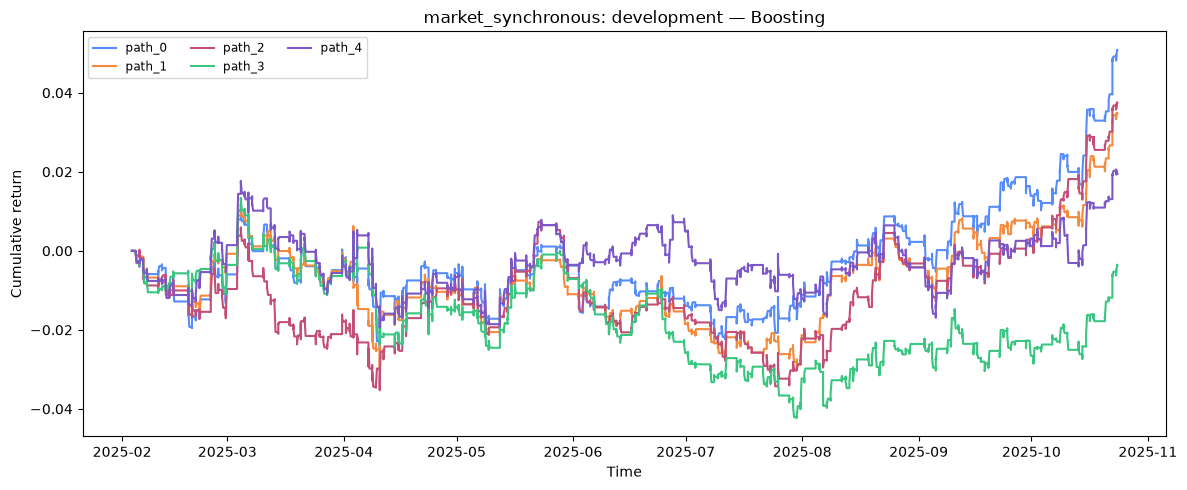

### Bagging: Backtest Statistics

path_0  \
section                  metric                          unit                                           
general_characteristics  start                           timestamp   2025-02-03 14:30:00.009395+00:00   
                         end                             timestamp          2025-10-23 20:00:00+00:00   
                         average_aum                     USD                            102674.573611   
                         leverage                        ratio                               0.514011   
                         maximum_dollar_position_size    USD                              78998.50403   
                         ratio_of_longs                  ratio                               0.500823   
                         frequency_of_bets               count/year                        2539.19409   
                         average_holding_period          days                                1.433684   
                         annualized_turnover             ratio                              263.31707   
                         correlation_to_underlying       ratio                               0.039142   
performance              pnl                             USD                              7376.848512   
                         annualized_rate_of_return       ratio                               0.104217   
                         pnl_from_long_positions         USD                              7335.907972   
                         pnl_from_short_positions        USD                                40.940539   
                         hit_ratio                       ratio                               0.508502   
                         average_return_from_hits        ratio                               0.001719   
                         average_return_from_misses      ratio                              -0.001618   
runs                     hhi_positive_returns            ratio                               0.001344   
                         hhi_negative_returns            ratio                               0.001198   
                         hhi_time_between_bets           ratio                                0.00081   
                         percentile_drawdown             ratio                               0.013262   
                         percentile_time_under_water     years                               0.048734   
implementation_shortfall broker_fees_per_turnover        ratio                                 0.0001   
                         average_slippage_per_turnover   ratio                                 0.0001   
                         dollar_performance_per_turnover ratio                                0.00038   
                         return_on_execution_costs       ratio                               1.900239   
efficiency               sharpe_ratio                    ratio                                0.06251   
                         annualized_sharpe_ratio         ratio                               1.194651   
                         probabilistic_sharpe_ratio      ratio                               0.566235   
classification_scores    primary_accuracy                score                               0.602891   
                         primary_precision               score                               0.592464   
                         primary_recall                  score                               0.719338   
                         primary_f1_score                score                               0.649766   
                         primary_negative_log_loss       score                              -0.658433   
                         meta_accuracy                   score                               0.603014   
                         meta_precision                  score                               0.603022   
                         meta_recall                     score                               0.999543   


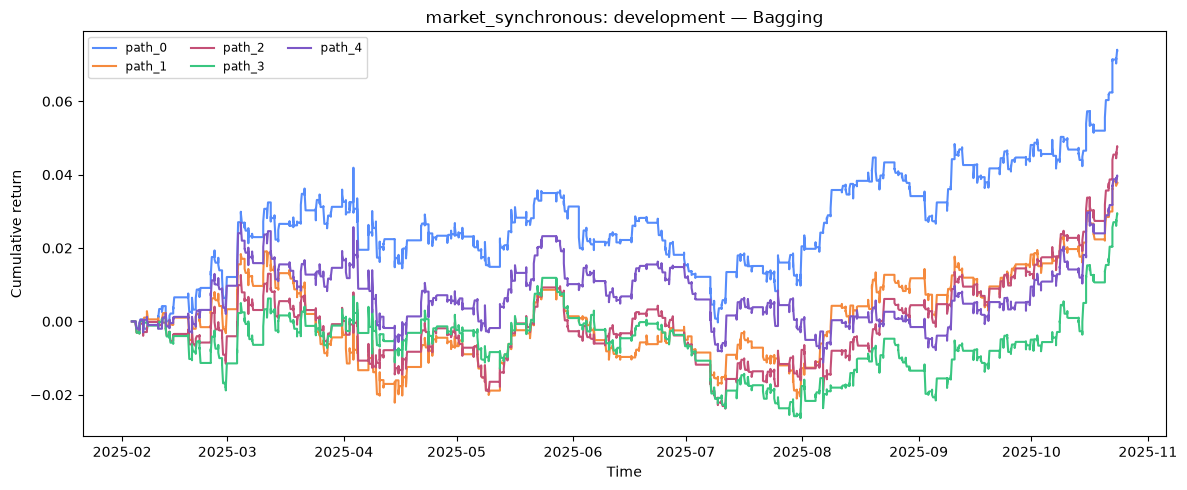

### Random Forest: Backtest Statistics

path_0  \
section                  metric                          unit                                           
general_characteristics  start                           timestamp   2025-02-03 14:30:00.009395+00:00   
                         end                             timestamp          2025-10-23 20:00:00+00:00   
                         average_aum                     USD                            102760.264397   
                         leverage                        ratio                               0.492092   
                         maximum_dollar_position_size    USD                             57741.655131   
                         ratio_of_longs                  ratio                               0.563576   
                         frequency_of_bets               count/year                        2103.22714   
                         average_holding_period          days                                 1.42978   
                         annualized_turnover             ratio                             250.762088   
                         correlation_to_underlying       ratio                               0.284788   
performance              pnl                             USD                              5798.564194   
                         annualized_rate_of_return       ratio                               0.081676   
                         pnl_from_long_positions         USD                               5570.80937   
                         pnl_from_short_positions        USD                               227.754824   
                         hit_ratio                       ratio                               0.509934   
                         average_return_from_hits        ratio                                  0.002   
                         average_return_from_misses      ratio                              -0.001923   
runs                     hhi_positive_returns            ratio                               0.002363   
                         hhi_negative_returns            ratio                               0.001698   
                         hhi_time_between_bets           ratio                               0.001757   
                         percentile_drawdown             ratio                               0.017498   
                         percentile_time_under_water     years                               0.086773   
implementation_shortfall broker_fees_per_turnover        ratio                                 0.0001   
                         average_slippage_per_turnover   ratio                                 0.0001   
                         dollar_performance_per_turnover ratio                               0.000313   
                         return_on_execution_costs       ratio                               1.567157   
efficiency               sharpe_ratio                    ratio                               0.039779   
                         annualized_sharpe_ratio         ratio                               0.760239   
                         probabilistic_sharpe_ratio      ratio                               0.416687   
classification_scores    primary_accuracy                score                               0.602891   
                         primary_precision               score                               0.592464   
                         primary_recall                  score                               0.719338   
                         primary_f1_score                score                               0.649766   
                         primary_negative_log_loss       score                              -0.658433   
                         meta_accuracy                   score                                0.56902   
                         meta_precision                  score                               0.695483   
                         meta_recall                     score                                0.50724   


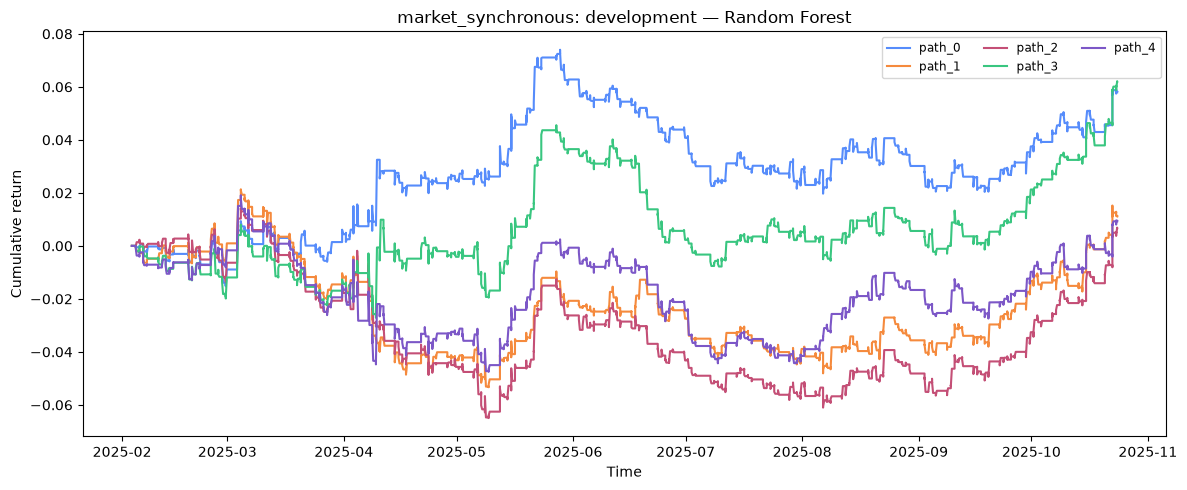

In [7]:
from IPython.display import Markdown

for family in ("boosting", "bagging", "random_forest"):
    family_name = family.replace("_", " ").title()
    family_statistics = statistics.loc[statistics["model_family"].eq(family)].set_index(
        ["section", "metric", "unit"],
    )
    display_values = family_statistics.drop(columns="model_family")
    display(Markdown(f"### {family_name}: Backtest Statistics"))
    with pd.option_context(
        "display.max_rows", None, "display.max_columns", None,
        "display.max_colwidth", None,
    ):
        display(display_values)

    fig, ax = plt.subplots(figsize=(12, 5))
    for (account_family, path), result in accounts.items():
        if account_family == family:
            ledger = result["ledger"]
            ax.plot(ledger.timestamp, ledger.aum / settings.initial_aum - 1, label=path)
    ax.set(
        title=f"{STRATEGY}: {PARTITION} — {family_name}",
        ylabel="Cumulative return", xlabel="Time",
    )
    ax.legend(fontsize="small", ncol=3)
    fig.tight_layout()
    plt.show()

In [8]:
result_directory = save_backtest_results(
    inputs, statistics,
    evaluation_settings=evaluation_settings, validation_settings=validation_settings,
)
print(result_directory)

/Users/kwonjunhyuk9/Documents/financial-machine-learning/data/backtesting/market_synchronous/development
